# Notebook 1: Channel Representations in Doubly Dispersive Propagation

This notebook visualizes how wireless channels appear in four equivalent signal-processing domains and shows why the delay-Doppler domain produces a particularly compact representation for high-mobility propagation scenarios.

Two channel families are used throughout:

- **Synthetic channels** defined by explicit delay-Doppler paths -- controlled examples designed to isolate individual propagation effects (delay dispersion, Doppler dispersion, fractional Doppler) one at a time.
- **OpenNTN channel realizations** from the 3GPP TR 38.811 model for Dense Urban, Urban, and Suburban NTN scenarios, showing the same representation pipeline applied to realistic channel conditions.

The four representations are introduced in the order they arise naturally from the physical propagation model:

1. **CIR** -- complex path coefficients $a_i(t)$ and delays $\tau_i$
2. **`h_time`** -- discrete time-varying impulse response $h[q, \ell]$
3. **`H_tf`** -- time-frequency channel $H[m, n]$, the OFDM-native view
4. **`H_dd`** -- delay-Doppler channel $H[\ell, k]$, the OTFS-native view

Tracing the same channel through all four representations makes the connections between them concrete. In particular, it shows directly why doubly dispersive channels that appear dense in the time-frequency domain have a sparse representation in the delay-Doppler domain -- the property that motivates OTFS modulation.

**The notebook covers:**
- `DDPathCIRGenerator` -- constructs Sionna-compatible CIR tensors from explicit delay-Doppler path parameters $(g_i, \ell_i, \kappa_i)$
- `NTNHardcodedCIRGenerator` -- TR 38.811 NTN channel realizations
- `cir_to_h_time` and `approximate_dd_paths_from_cir` from `otfs_sim.phy.channel.channel_utils`
- Synthetic channel cases: static multipath, pure Doppler, sparse doubly dispersive, fractional Doppler
- OpenNTN scenarios: Dense Urban, Urban, Suburban at a LEO satellite elevation

**Key observations covered:**
- Static multipath produces sparse, time-invariant structure in all domains; adding Doppler breaks time-invariance and densifies the time-frequency view
- Doppler appears as linear phase evolution in `h_time` and as sinc leakage in `H_dd` when the Doppler tap is fractional
- The delay-Doppler representation has at most $P$ non-zero entries for a $P$-path channel, regardless of frame size -- in contrast to the dense $M \times N$ time-frequency channel
- NTN channels are dominated by a single large Doppler shift from the satellite velocity; the delay spread is small relative to the delay resolution

---

**Table of Contents**

- [1. Imports and Frame Parameters](#1-imports-and-frame-parameters)
- [2. Synthetic Channels Defined by Delay-Doppler Paths](#2-synthetic-channels-defined-by-delay-doppler-paths)
- [3. Channel Impulse Response: Path Gains and Delays](#3-channel-impulse-response-path-gains-and-delays)
  - [3.1 Complex Path-Coefficient Trajectories](#31-complex-path-coefficient-trajectories)
  - [3.2 Path Amplitude over Time](#32-path-amplitude-over-time)
  - [3.3 Path Phase over Time](#33-path-phase-over-time)
- [4. Discrete Time-Varying Channel Impulse Response `h_time`](#4-discrete-time-varying-channel-impulse-response-h_time)
  - [4.1 Magnitude of `h_time`](#41-magnitude-of-h_time)
  - [4.2 Phase of `h_time`](#42-phase-of-h_time)
- [5. Time-Frequency Channel Representation](#5-time-frequency-channel-representation)
- [6. Delay-Doppler Channel Representation](#6-delay-doppler-channel-representation)
- [7. OpenNTN Channel Realizations](#7-openntn-channel-realizations)
  - [7.1 OpenNTN CIR: Path Coefficient Trajectories](#71-openntn-cir-path-coefficient-trajectories)
  - [7.2 OpenNTN CIR: Path Amplitude over Time](#72-openntn-cir-path-amplitude-over-time)
  - [7.3 OpenNTN CIR: Path Phase over Time](#73-openntn-cir-path-phase-over-time)
  - [7.4 OpenNTN `h_time`: Magnitude and Phase](#74-openntn-h_time-magnitude-and-phase)
  - [7.5 OpenNTN Time-Frequency Representation](#75-openntn-time-frequency-representation)
  - [7.6 OpenNTN Approximate Delay-Doppler Representation](#76-openntn-approximate-delay-doppler-representation)
- [8. Summary](#8-summary)

## 1. Imports and Frame Parameters

Only the repository blocks used for channel generation and conversion are imported here. Plotting is intentionally kept inline in each section so that each figure can be directly associated with the code that produces it.

Two numbers set the resolution budget for the entire frame:

- **M** (delay bins / subcarriers): fixes the delay resolution to $1 / (M \cdot \Delta f)$. A larger $M$ resolves closer-spaced multipath arrivals but increases the OFDM symbol duration.
- **N** (Doppler bins / OFDM symbols): the frame duration $N \cdot T$ fixes the Doppler resolution to $1 / (N \cdot T)$. A larger $N$ resolves slower relative velocities but increases the overall frame length.

`L_MAX` is the maximum channel delay tap the receiver will model. Any energy arriving more than $L_\text{MAX} / (M \cdot \Delta f)$ seconds after the first path is ignored.

In [1]:

from pathlib import Path
import sys

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Find repository root from the current notebook location
path = Path.cwd().resolve()
for candidate in [path] + list(path.parents):
    if (candidate / "src").exists():
        ROOT = candidate
        break
else:
    raise RuntimeError("Could not find repository root containing src/.")

sys.path.append(str(ROOT / "src"))

from otfs_sim.phy.channel.generate_channel_cir import (
    DDPathCIRGenerator,
    NTNHardcodedCIRGenerator,
)

from otfs_sim.phy.channel.channel_utils import (
    cir_to_h_time,
    approximate_dd_paths_from_cir,
)

# Frame/numerology parameters
M = 32                         # delay bins / subcarriers
N = 16                         # Doppler bins / OFDM symbols
CP_LEN = 8                     # cyclic prefix length
SUBCARRIER_SPACING = 15e3
BANDWIDTH = M * SUBCARRIER_SPACING

NUM_TIME_SAMPLES_NO_CP = N * M
NUM_TIME_SAMPLES_WITH_CP = N * (M + CP_LEN)

L_MIN = 0
L_MAX = 16

BATCH_SIZE = 1


I0000 00:00:1793615233.310579   16631 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793615233.625463   16631 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793615235.744806   16631 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## 2. Synthetic Channels Defined by Delay-Doppler Paths

Each synthetic channel is a sum of $P$ propagation paths. Path $i$ contributes a complex amplitude $g_i$, arrives with a discrete delay tap $\ell_i$ (in units of the sampling interval $1/(M \cdot \Delta f)$), and introduces a Doppler shift $\kappa_i$ (in units of the Doppler bin spacing $1/(N \cdot T)$).

The parameters passed to `DDPathCIRGenerator` are:

- `g_i`: complex path gains
- `l_i`: discrete delay taps $\ell_i$
- `k_i`: Doppler taps $\kappa_i$

Four cases are defined, each isolating one propagation effect:

| Case | $\ell_i$ | $\kappa_i$ | Effect |
|---|---|---|---|
| Static multipath | $\ell_i \neq 0$ | $\kappa_i = 0$ | Frequency-selective fading; no time variation |
| Pure Doppler | $\ell_i = 0$ | $\kappa_i \neq 0$ | Time-selective fading; no delay spread |
| Sparse doubly dispersive | $\ell_i \neq 0$ | $\kappa_i \in \mathbb{Z} \setminus \{0\}$ | General high-mobility case |
| Fractional Doppler | $\ell_i \neq 0$ | $\kappa_i \notin \mathbb{Z}$ | Off-grid Doppler; sinc leakage across Doppler bins |

These are controlled examples, not meant to be realistic channels. The fractional Doppler case is included to demonstrate the leakage pattern that arises when a path does not fall on an integer Doppler bin -- the main source of off-grid interference in OTFS systems.

In [2]:
# Keep the synthetic cases explicit so each channel effect can be changed easily.
synthetic_channels = {
    "Static multipath": {
        "g_i": [1.0 + 0.0j, 0.65 + 0.25j, 0.35 - 0.15j],
        "l_i": [0, 5, 11],
        "k_i": [0.0, 0.0, 0.0],
    },
    "Pure Doppler": {
        "g_i": [1.0 + 0.0j, 0.65 + 0.35j],
        "l_i": [0, 0],
        "k_i": [0.0, 4.0],
    },
    "Sparse doubly dispersive": {
        "g_i": [1.0 + 0.0j, 0.75 + 0.20j, 0.45 - 0.25j, 0.25 + 0.35j],
        "l_i": [0, 3, 8, 13],
        "k_i": [0.0, 2.0, -3.0, 5.0],
    },
    "Fractional Doppler": {
        "g_i": [1.0 + 0.0j, 0.7 + 0.25j, 0.4 - 0.2j],
        "l_i": [0, 5, 10],
        "k_i": [0.0, 2.7, -3.4],
    },
}

for name, ch in synthetic_channels.items():
    print(f"\n{name}")
    print("g_i:", ch["g_i"])
    print("l_i:", ch["l_i"])
    print("k_i:", ch["k_i"])



Static multipath
g_i: [(1+0j), (0.65+0.25j), (0.35-0.15j)]
l_i: [0, 5, 11]
k_i: [0.0, 0.0, 0.0]

Pure Doppler
g_i: [(1+0j), (0.65+0.35j)]
l_i: [0, 0]
k_i: [0.0, 4.0]

Sparse doubly dispersive
g_i: [(1+0j), (0.75+0.2j), (0.45-0.25j), (0.25+0.35j)]
l_i: [0, 3, 8, 13]
k_i: [0.0, 2.0, -3.0, 5.0]

Fractional Doppler
g_i: [(1+0j), (0.7+0.25j), (0.4-0.2j)]
l_i: [0, 5, 10]
k_i: [0.0, 2.7, -3.4]


## 3. Channel Impulse Response: Path Gains and Delays

The starting point for all further representations is the continuous-time channel impulse response (CIR) in Sionna's format:

- `a`: complex path coefficients over time, shape `[batch, rx, rx_ant, tx, tx_ant, num_paths, num_time_steps]`
- `tau`: path delays in seconds, shape `[batch, rx, tx, num_paths]`

For a channel with $P$ paths, path $i$ contributes to the received signal as

$$r(t) = \sum_i a_i(t) \cdot s(t - \tau_i)$$

where $a_i(t) = g_i \cdot e^{j 2\pi \nu_i t}$ is the time-varying complex amplitude caused by the Doppler shift $\nu_i$.

Three views of the CIR are shown below:

1. **Complex path-coefficient trajectories** -- $a_i(t)$ traced in the complex plane over the full frame duration. A static path ($\kappa_i = 0$) stays at a fixed point; a Doppler-shifted path rotates at a rate proportional to $\kappa_i$. The radius equals $|g_i|$.
2. **Path amplitude over time** -- $|a_i(t)|$ as a heatmap. In this model path amplitudes are constant within the frame (no fast fading), so the magnitude plot shows flat-coloured horizontal bands. This per-path invariance is the assumption that makes OTFS channel estimation tractable.
3. **Path phase over time** -- $\angle a_i(t)$. The phase of a static path is constant; a Doppler-shifted path shows a linear ramp at rate $\nu_i$.

In [3]:
# Convert each hand-defined DD path set into Sionna-compatible CIR tensors.
synthetic_data = {}

for name, ch in synthetic_channels.items():
    generator = DDPathCIRGenerator(
        g_i=ch["g_i"],
        l_i=ch["l_i"],
        k_i=ch["k_i"],
    )

    a, tau = generator(
        batch_size=BATCH_SIZE,
        num_time_steps=NUM_TIME_SAMPLES_WITH_CP,
        bandwidth=BANDWIDTH,
    )

    synthetic_data[name] = {
        "a": a,
        "tau": tau,
        "g_i": tf.constant(ch["g_i"], dtype=tf.complex64),
        "l_i": tf.constant(ch["l_i"], dtype=tf.int32),
        "k_i": tf.constant(ch["k_i"], dtype=tf.float32),
    }

    print(f"{name:28s} a shape: {a.shape}, tau shape: {tau.shape}")


Static multipath             a shape: (1, 1, 1, 1, 1, 3, 640), tau shape: (1, 1, 1, 3)
Pure Doppler                 a shape: (1, 1, 1, 1, 1, 2, 640), tau shape: (1, 1, 1, 2)
Sparse doubly dispersive     a shape: (1, 1, 1, 1, 1, 4, 640), tau shape: (1, 1, 1, 4)
Fractional Doppler           a shape: (1, 1, 1, 1, 1, 3, 640), tau shape: (1, 1, 1, 3)


E0000 00:00:1793615350.977657   16631 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


### 3.1 Complex Path-Coefficient Trajectories

Each subplot shows one synthetic channel. Each coloured trajectory corresponds to one path coefficient $a_i(t)$ evolving in the complex plane over the full frame duration. The cross marker (x) indicates the initial value $a_i(0)$.

For static paths ($\kappa_i = 0$) the trajectory is a single stationary point. For Doppler-shifted paths the trajectory is a circle whose radius is $|g_i|$ and whose angular rate is $2\pi\nu_i$. The fractional Doppler paths trace the same circular arcs as their nearest integer-bin neighbours -- the fractional offset is not visible at this level of representation.

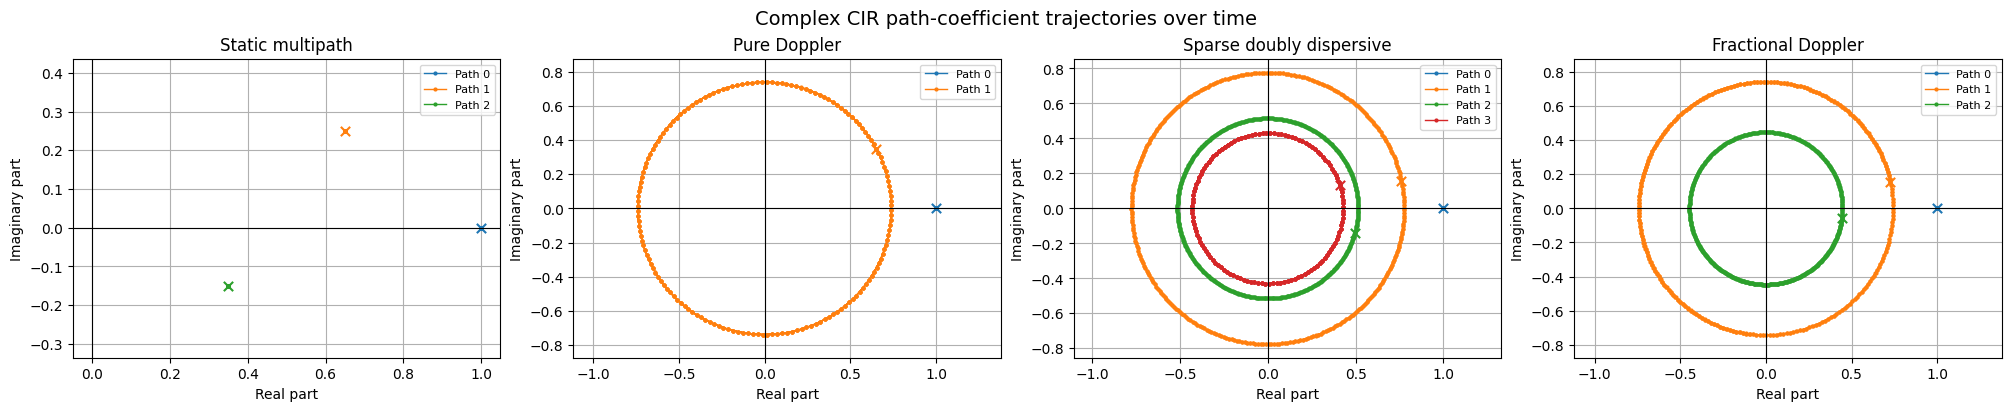

In [4]:
fig, axes = plt.subplots(1, len(synthetic_data), figsize=(5 * len(synthetic_data), 4), constrained_layout=True)

for ax, (name, data) in zip(axes, synthetic_data.items()):
    a = data["a"].numpy()[0, 0, 0, 0, 0, :, :]  # [num_paths, num_time_steps]
    num_paths = a.shape[0]

    for p in range(num_paths):
        ax.plot(
            np.real(a[p, :]),
            np.imag(a[p, :]),
            marker="o",
            markersize=2,
            linewidth=1.0,
            label=f"Path {p}",
        )
        ax.scatter(np.real(a[p, 0]), np.imag(a[p, 0]), s=45, marker="x")

    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(name)
    ax.set_xlabel("Real part")
    ax.set_ylabel("Imaginary part")
    ax.grid(True)
    ax.axis("equal")
    ax.legend(fontsize=8)

fig.suptitle("Complex CIR path-coefficient trajectories over time", fontsize=14)
plt.show()


### 3.2 Path Amplitude over Time

The rows correspond to paths and the columns to time samples. A global normalization is applied per channel for visualization.

Because path amplitudes are constant within the frame in this model, the heatmap shows uniform horizontal bands. The relative brightness of the bands reflects the relative path gain $|g_i|$.

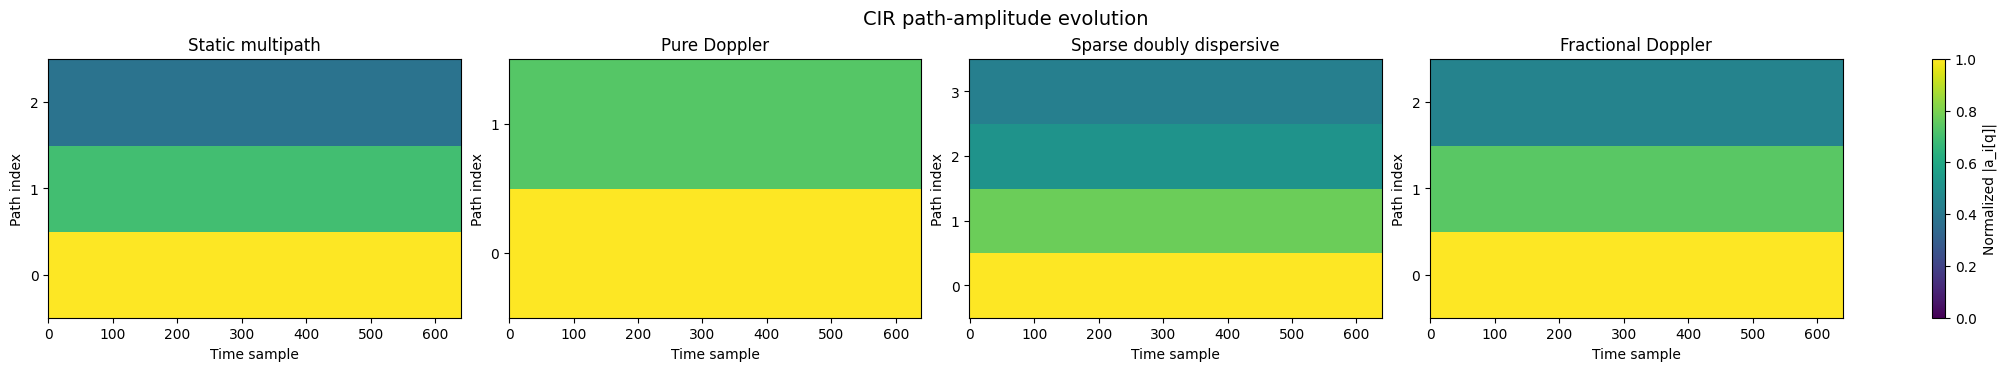

In [5]:
fig, axes = plt.subplots(1, len(synthetic_data), figsize=(5 * len(synthetic_data), 3.6), constrained_layout=True)

for ax, (name, data) in zip(axes, synthetic_data.items()):
    # Sionna CIR shape after indexing:
    # a -> [num_paths, num_time_steps]
    a = data["a"].numpy()[0, 0, 0, 0, 0, :, :]
    amp = np.abs(a)
    amp = amp / (np.max(amp) + 1e-12)

    im = ax.imshow(
        amp,
        aspect="auto",
        origin="lower",
        cmap="viridis",
        vmin=0,
        vmax=1,
        interpolation="nearest",
    )
    ax.set_title(name)
    ax.set_xlabel("Time sample")
    ax.set_ylabel("Path index")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

fig.colorbar(im, ax=axes.ravel().tolist(), label="Normalized |a_i[q]|")
fig.suptitle("CIR path-amplitude evolution", fontsize=14)
plt.show()


### 3.3 Path Phase over Time

Doppler appears most directly as linear phase evolution of the path coefficients. The phase of path $i$ evolves as

$$\angle a_i(t) = \angle g_i + 2\pi \nu_i t$$

For static paths the phase is constant. For Doppler-shifted paths the phase ramps linearly; the slope is proportional to $\kappa_i$. Fractional Doppler paths produce the same ramp slope as their nominal Doppler value -- the fractional offset manifests only after projection onto the discrete delay-Doppler grid, as seen in Section 6.

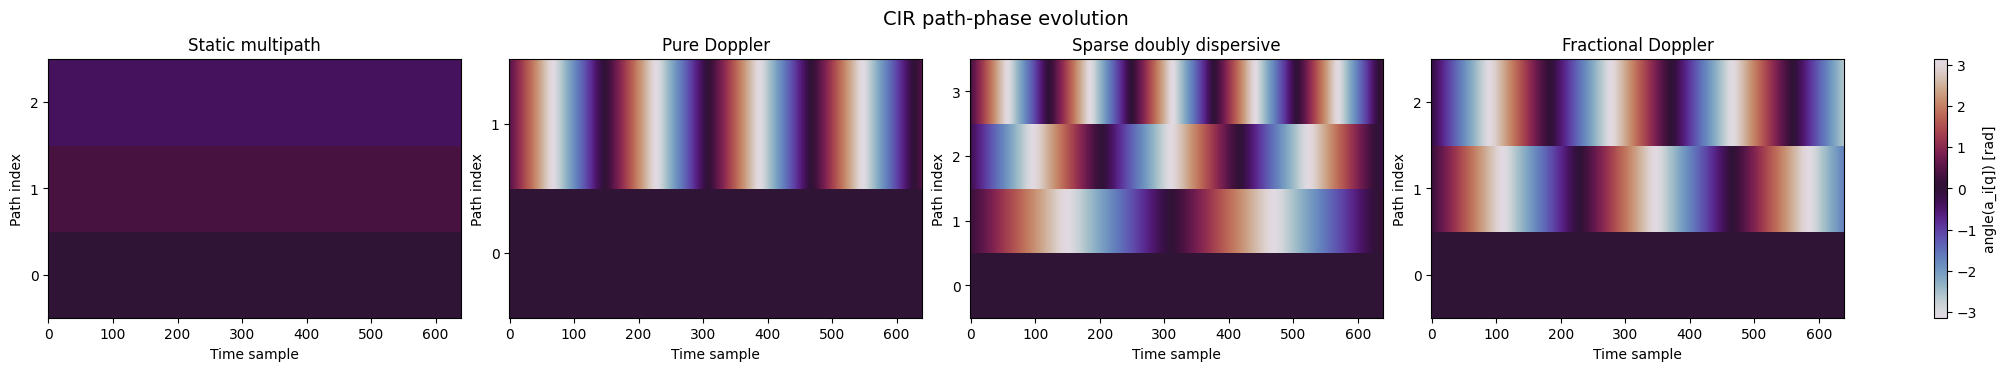

In [6]:
fig, axes = plt.subplots(1, len(synthetic_data), figsize=(5 * len(synthetic_data), 3.6), constrained_layout=True)

for ax, (name, data) in zip(axes, synthetic_data.items()):
    a = data["a"].numpy()[0, 0, 0, 0, 0, :, :]
    phase = np.angle(a)

    im = ax.imshow(
        phase,
        aspect="auto",
        origin="lower",
        cmap="twilight",
        vmin=-np.pi,
        vmax=np.pi,
        interpolation="nearest",
    )
    ax.set_title(name)
    ax.set_xlabel("Time sample")
    ax.set_ylabel("Path index")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

fig.colorbar(im, ax=axes.ravel().tolist(), label="angle(a_i[q]) [rad]")
fig.suptitle("CIR path-phase evolution", fontsize=14)
plt.show()


## 4. Discrete Time-Varying Channel Impulse Response `h_time`

The continuous CIR is sampled at the receiver's sampling rate $f_s = M \cdot \Delta f$ to give the discrete time-varying impulse response $h[q, \ell]$, with shape `[time_samples, delay_taps]`.

This is the object that directly governs how a transmitted sample $s[q - \ell]$ contributes to the received sample $r[q]$:

$$r[q] = \sum_{\ell=0}^{L_\text{max}} h[q, \ell] \cdot s[q - \ell]$$

The resulting `h_time` tensor has shape `[batch, rx, rx_ant, tx, tx_ant, time, delay]`. The important view is the 2D slice `[time, delay]` for the SISO case.

`h_time` is the representation that `BlockLMMSEEqualizer` works with. Every other representation -- the Sionna CIR tensor, the delay-Doppler channel matrix -- ultimately converts back to `h_time` before any time-domain processing.

In [7]:
# Convert Sionna CIR tensors into the discrete time-varying taps used by ApplyTimeChannel.
for name, data in synthetic_data.items():
    h_time, l_min_used, l_max_used = cir_to_h_time(
        a=data["a"],
        tau=data["tau"],
        bandwidth=BANDWIDTH,
        l_min=L_MIN,
        l_max=L_MAX,
        normalize=False,
    )
    synthetic_data[name]["h_time"] = h_time
    synthetic_data[name]["l_min_used"] = l_min_used
    synthetic_data[name]["l_max_used"] = l_max_used

    print(f"{name:28s} h_time shape: {h_time.shape}, l_min={l_min_used}, l_max={l_max_used}")


Static multipath             h_time shape: (1, 1, 1, 1, 1, 640, 17), l_min=0, l_max=16
Pure Doppler                 h_time shape: (1, 1, 1, 1, 1, 640, 17), l_min=0, l_max=16
Sparse doubly dispersive     h_time shape: (1, 1, 1, 1, 1, 640, 17), l_min=0, l_max=16
Fractional Doppler           h_time shape: (1, 1, 1, 1, 1, 640, 17), l_min=0, l_max=16


### 4.1 Magnitude of `h_time`

Active delay taps appear as bright horizontal lines. Their positions on the delay axis directly reflect the physical path delays expressed in units of the sampling interval $1/f_s$.

For static channels ($\kappa_i = 0$) the tap magnitudes are constant over time. For Doppler channels the magnitude profile is also constant over time -- the Doppler shift modulates the phase of each tap, not its magnitude.

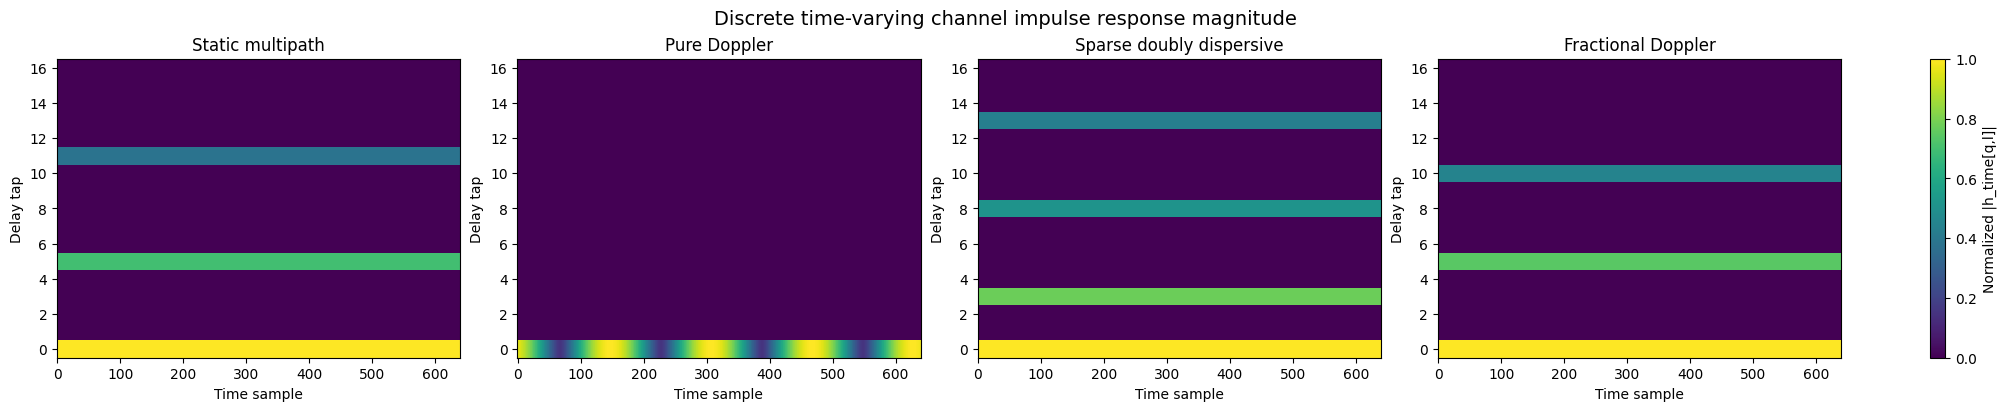

In [8]:
fig, axes = plt.subplots(1, len(synthetic_data), figsize=(5 * len(synthetic_data), 4), constrained_layout=True)

for ax, (name, data) in zip(axes, synthetic_data.items()):
    # h_time after indexing has shape [time, delay].
    # Transpose for plotting as [delay, time].
    h = data["h_time"].numpy()[0, 0, 0, 0, 0, :, :]  # [time, delay]
    h_abs = np.abs(h).T  # [delay, time]
    h_abs = h_abs / (np.max(h_abs) + 1e-12)

    im = ax.imshow(
        h_abs,
        aspect="auto",
        origin="lower",
        cmap="viridis",
        vmin=0,
        vmax=1,
        interpolation="nearest",
    )
    ax.set_title(name)
    ax.set_xlabel("Time sample")
    ax.set_ylabel("Delay tap")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

fig.colorbar(im, ax=axes.ravel().tolist(), label="Normalized |h_time[q,l]|")
fig.suptitle("Discrete time-varying channel impulse response magnitude", fontsize=14)
plt.show()


### 4.2 Phase of `h_time`

For a path with Doppler tap $\kappa$ the phase at delay $\ell$ and time $q$ evolves approximately as

$$\angle h[q, \ell] \approx \angle g_i + \kappa \cdot \frac{q - \ell}{NM} \cdot 2\pi$$

The phase ramp is clearly visible in the Doppler cases. For the static case the phase is constant. Fractional Doppler produces a ramp at a non-integer rate, which is why the estimator in Notebook 4 must handle sub-bin leakage explicitly.

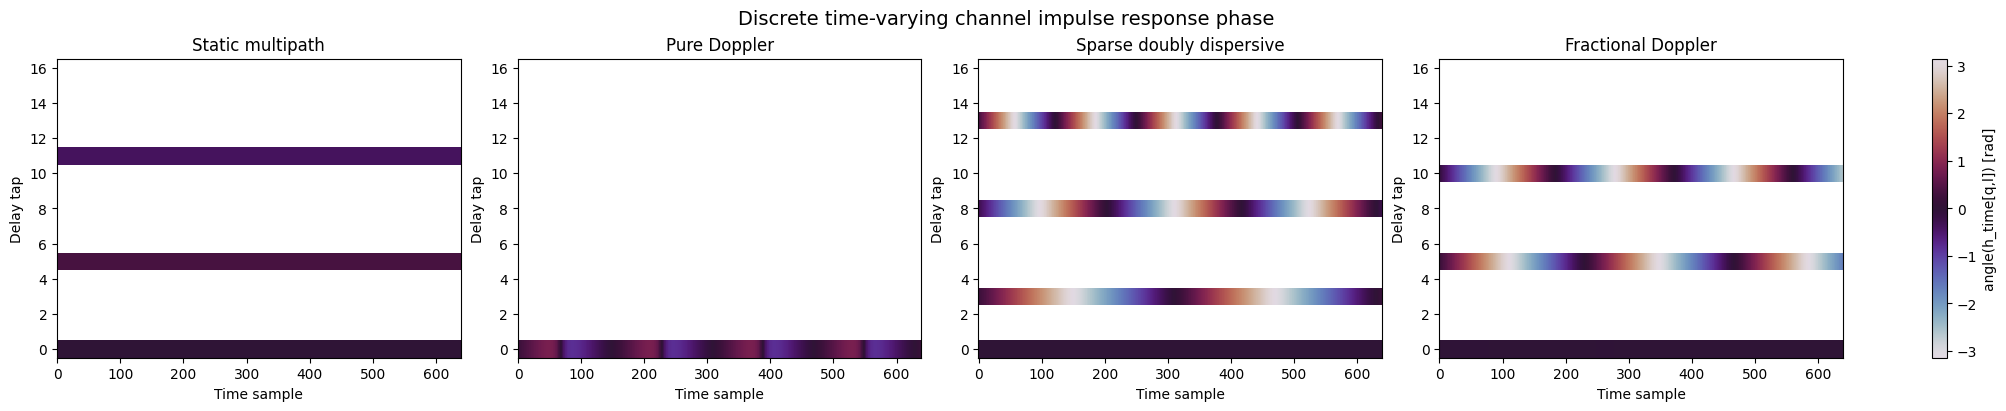

In [19]:

fig, axes = plt.subplots(1, len(synthetic_data), figsize=(5 * len(synthetic_data), 4), constrained_layout=True)

for ax, (name, data) in zip(axes, synthetic_data.items()):
    h = data["h_time"].numpy()[0, 0, 0, 0, 0, :, :]
    phase = np.angle(h).T

    # Mask phase values at numerically zero taps to avoid plotting meaningless phase.
    mask = np.abs(h).T < 1e-6
    phase = np.ma.array(phase, mask=mask)

    im = ax.imshow(
        phase,
        aspect="auto",
        origin="lower",
        cmap="twilight",
        vmin=-np.pi,
        vmax=np.pi,
        interpolation="nearest",
    )
    ax.set_title(name)
    ax.set_xlabel("Time sample")
    ax.set_ylabel("Delay tap")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

fig.colorbar(im, ax=axes.ravel().tolist(), label="angle(h_time[q,l]) [rad]")
fig.suptitle("Discrete time-varying channel impulse response phase", fontsize=14)
plt.show()


## 5. Time-Frequency Channel Representation

The time-frequency channel $H_\text{tf}[m, n]$ is obtained by taking an $M$-point DFT of the delay dimension of `h_time` at the start of each OFDM symbol period:

$$H_\text{tf}[m, n] = \sum_{\ell=0}^{M-1} h\bigl[n(M+L_\text{CP}) + L_\text{CP},\, \ell\bigr] \cdot e^{-j 2\pi m \ell / M}$$

This is the channel view that OFDM naturally operates on. For a static multipath channel $H_\text{tf}[m, n]$ does not depend on $n$ -- the channel is the same for every OFDM symbol and equalization reduces to a single complex division per subcarrier.

When the channel is time-varying (Doppler), $H_\text{tf}[m, n]$ changes with $n$. The magnitude plot becomes non-uniform across the time axis, and the phase plot shows Doppler-induced variation sweeping across both time and frequency dimensions.

For doubly dispersive channels the time-frequency channel is dense: $P$ propagation paths spread their energy across all $M \times N$ time-frequency resources. Estimating $H_\text{tf}[m, n]$ directly would require pilot overhead proportional to the frame size -- in contrast to the delay-Doppler representation shown next.

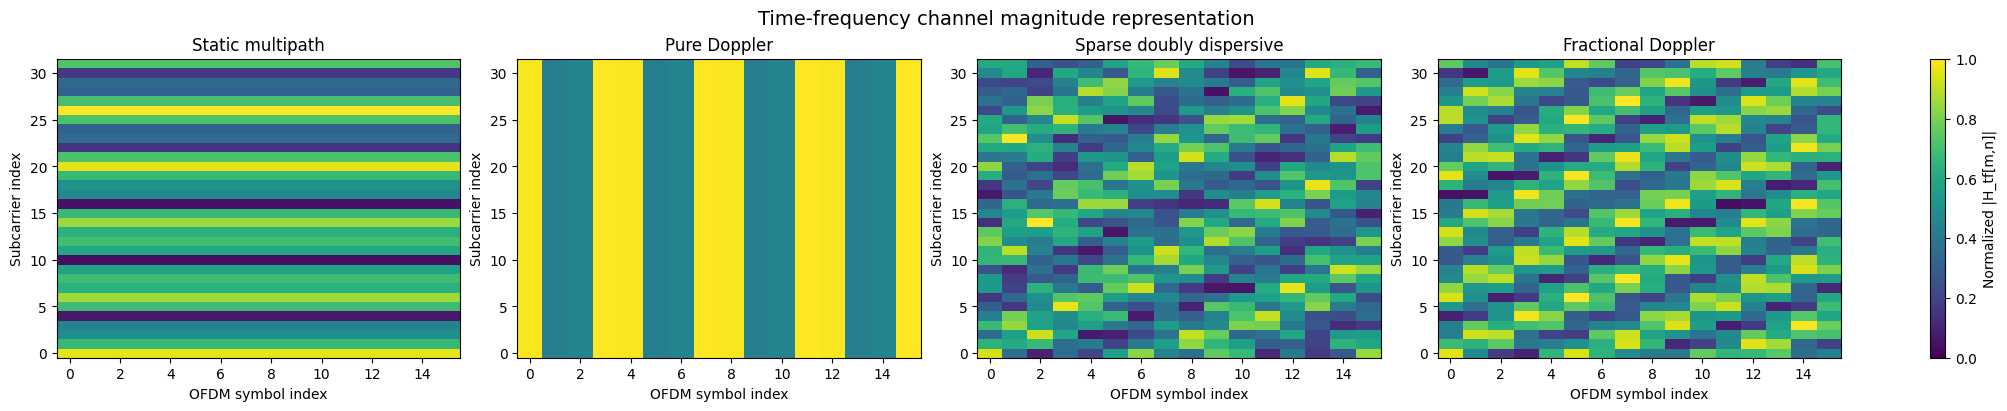

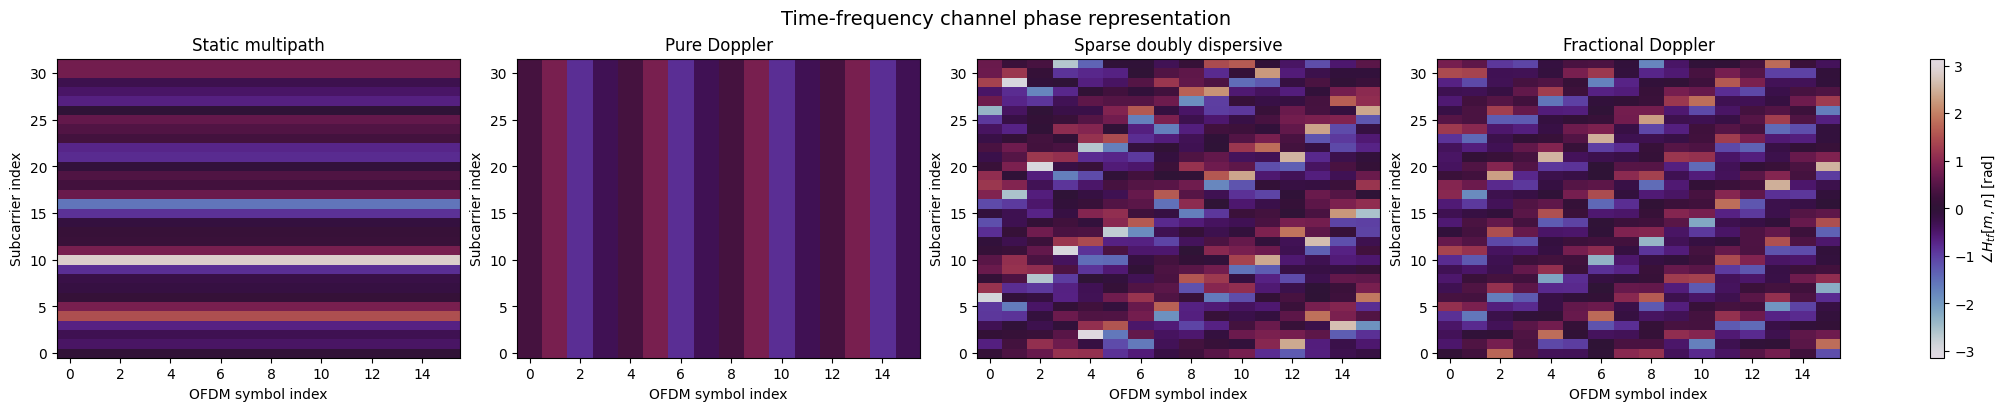

In [10]:
for name, data in synthetic_data.items():
    h = data["h_time"].numpy()[0, 0, 0, 0, 0, :, :]  # [time, delay]
    num_delays = h.shape[1]

    H_tf = np.zeros((N, M), dtype=np.complex128)  # [OFDM symbol, subcarrier]

    for n in range(N):
        # Sample one delay profile per OFDM symbol, after CP removal.
        q = n * (M + CP_LEN) + CP_LEN
        # Zero-pad the delay taps to length M before taking the FFT over delay.
        h_delay = np.zeros(M, dtype=np.complex128)
        h_delay[:min(num_delays, M)] = h[q, :min(num_delays, M)]
        H_tf[n, :] = np.fft.fft(h_delay, n=M)

    synthetic_data[name]["H_tf"] = H_tf


fig, axes = plt.subplots(
    1,
    len(synthetic_data),
    figsize=(5 * len(synthetic_data), 4),
    constrained_layout=True,
)

for ax, (name, data) in zip(axes, synthetic_data.items()):
    # H_tf is stored as [OFDM symbol, subcarrier].
    # Transpose for plotting as [subcarrier, OFDM symbol].
    H_abs = np.abs(data["H_tf"]).T  # [subcarrier, OFDM symbol]
    H_abs = H_abs / (np.max(H_abs) + 1e-12)

    im = ax.imshow(
        H_abs,
        aspect="auto",
        origin="lower",
        cmap="viridis",
        vmin=0,
        vmax=1,
    )

    ax.set_title(name)
    ax.set_xlabel("OFDM symbol index")
    ax.set_ylabel("Subcarrier index")

fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    label="Normalized |H_tf[m,n]|",
)

fig.suptitle(
    "Time-frequency channel magnitude representation",
    fontsize=14,
)

plt.show()

fig, axes = plt.subplots(
    1,
    len(synthetic_data),
    figsize=(5 * len(synthetic_data), 4),
    constrained_layout=True,
)

for ax, (name, data) in zip(axes, synthetic_data.items()):
    H_phase = np.angle(data["H_tf"]).T  # [subcarrier, OFDM symbol]

    im = ax.imshow(
        H_phase,
        aspect="auto",
        origin="lower",
        cmap="twilight",
        vmin=-np.pi,
        vmax=np.pi,
    )

    ax.set_title(name)
    ax.set_xlabel("OFDM symbol index")
    ax.set_ylabel("Subcarrier index")

fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    label=r"$\angle H_{tf}[m,n]$ [rad]",
)

fig.suptitle(
    "Time-frequency channel phase representation",
    fontsize=14,
)

plt.show()


## 6. Delay-Doppler Channel Representation

For a channel with $P$ paths, each path contributes a single non-zero entry at its $(\ell_i, \kappa_i)$ grid location:

$$H_\text{dd}[\ell, k] = \sum_i g_i \cdot \delta[\ell - \ell_i] \cdot \delta[k - \kappa_i]$$

The result is a sparse 2D image with at most $P$ non-zero pixels -- one per propagation path -- regardless of the frame size $M \times N$. This is the fundamental sparsity argument behind OTFS: a channel that is dense in the time-frequency domain has a compact description in the delay-Doppler domain.

Two versions are plotted:

- **Integer-bin**: each path is placed at the nearest integer $(\ell, k)$. For integer Doppler channels this is exact; the image is maximally sparse.
- **Sinc-spread**: for fractional Doppler, each path is convolved with a periodic sinc kernel of width $N$ bins. The energy of a single path spreads across all $N$ Doppler bins, decaying away from the true Doppler value. A threshold-based estimator will find the main lobe but miss or misattribute the sidelobes.

Comparing these sparse delay-Doppler images to the dense time-frequency images from Section 5 illustrates the key motivation for OTFS: fewer parameters means less pilot overhead and a structurally simpler estimation problem.

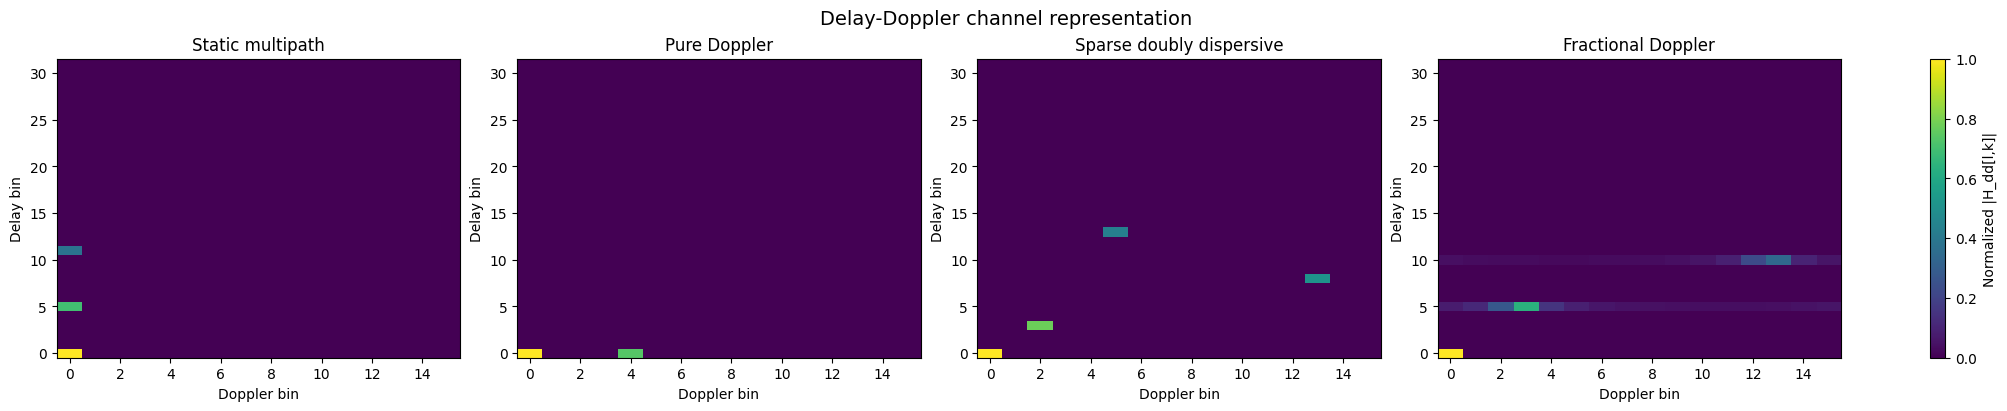

In [11]:

for name, data in synthetic_data.items():
    g_i = data["g_i"].numpy()
    l_i = data["l_i"].numpy()
    k_i = data["k_i"].numpy()

    H_dd = np.zeros((M, N), dtype=np.complex128)  # [delay, doppler]

    doppler_bins = np.arange(N)

    for g, ell, k in zip(g_i, l_i, k_i):
        ell = int(ell)

        if ell < 0 or ell >= M:
            continue

        # Integer Doppler: place the path in one bin.
        if np.isclose(k, np.round(k)):
            kk = int(np.round(k)) % N
            H_dd[ell, kk] += g

        # Fractional Doppler: visualize leakage over Doppler bins.
        else:
            centered_bins = np.arange(-N // 2, N // 2)
            leakage = np.zeros(N, dtype=np.complex128)

            for idx, kk_centered in enumerate(centered_bins):
                x = k - kk_centered
                if np.isclose(x, 0.0):
                    leakage[idx] = 1.0
                else:
                    leakage[idx] = (
                        np.sin(np.pi * x)
                        / (N * np.sin(np.pi * x / N))
                        * np.exp(1j * np.pi * x * (N - 1) / N)
                    )

            # Map centered Doppler bins to [0, N-1]
            for idx, kk_centered in enumerate(centered_bins):
                kk = int(kk_centered) % N
                H_dd[ell, kk] += g * leakage[idx]

    synthetic_data[name]["H_dd"] = H_dd

fig, axes = plt.subplots(1, len(synthetic_data), figsize=(5 * len(synthetic_data), 4), constrained_layout=True)

for ax, (name, data) in zip(axes, synthetic_data.items()):
    H_abs = np.abs(data["H_dd"])
    H_abs = H_abs / (np.max(H_abs) + 1e-12)

    im = ax.imshow(
        H_abs,
        aspect="auto",
        origin="lower",
        cmap="viridis",
        vmin=0,
        vmax=1,
    )
    ax.set_title(name)
    ax.set_xlabel("Doppler bin")
    ax.set_ylabel("Delay bin")

fig.colorbar(im, ax=axes.ravel().tolist(), label="Normalized |H_dd[l,k]|")
fig.suptitle("Delay-Doppler channel representation", fontsize=14)
plt.show()


## 7. OpenNTN Channel Realizations

The same representation pipeline is now applied to realistic OpenNTN channel realizations generated from the 3GPP TR 38.811 model for a low-Earth-orbit satellite link.

The three scenarios differ in multipath richness:

- **Dense Urban** (`dur`) -- highest multipath richness, widest delay spread.
- **Urban** (`urb`) -- fewer paths, tightly clustered in delay.
- **Suburban** (`sur`) -- very tightly clustered paths, approaching a near-line-of-sight scenario.

Unlike the synthetic channels, these realizations are not constructed from a small list of explicit paths. The CIR is generated by the Sionna/OpenNTN TR 38.811 implementation, which draws path parameters from empirical distributions calibrated to satellite link measurements.

For all three scenarios the Doppler shift is dominated by the satellite velocity rather than the terminal velocity. The approximate DD paths extracted in Section 7.6 confirm this: all paths fall on nearly the same Doppler bin for each scenario, reflecting the satellite's large relative velocity component along the link. The delay-Doppler plots also illustrate a practical limitation of sparse representation: when several paths share nearly the same Doppler shift they cluster in the DD plane and cannot be individually resolved by threshold-based detection.

In [12]:
# Larger NTN numerology keeps the realistic channel delay resolution reasonable.
NTN_NUM_OFDM_SYMBOLS = 64
NTN_FFT_SIZE = 256
NTN_CP_LEN = 32

NTN_SUBCARRIER_SPACING = 120e3
NTN_BANDWIDTH = NTN_FFT_SIZE * NTN_SUBCARRIER_SPACING

NTN_NUM_TIME_SAMPLES_WITH_CP = (
    NTN_NUM_OFDM_SYMBOLS
    * (NTN_FFT_SIZE + NTN_CP_LEN)
)

NTN_NUM_TIME_SAMPLES_NO_CP = (
    NTN_NUM_OFDM_SYMBOLS
    * NTN_FFT_SIZE
)

NTN_L_MIN = 0
NTN_L_MAX = 32

ntn_scenarios = {
    "Dense Urban": "dur",
    "Urban": "urb",
    "Suburban": "sur",
}

ntn_data = {}
# Generate one OpenNTN realization per scenario and convert it to h_time.
for label, scenario in ntn_scenarios.items():
    generator = NTNHardcodedCIRGenerator(
        scenario=scenario,
        carrier_frequency=2.0e9,
        direction="downlink",
        elevation_angle=70.0,
        satellite_height=600000.0,
        num_ut=1,
        doppler_enabled=True,
    )

    a, tau = generator(
        batch_size=BATCH_SIZE,
        num_time_steps=NTN_NUM_TIME_SAMPLES_WITH_CP,
        bandwidth=NTN_BANDWIDTH,
    )

    h_time, l_min_used, l_max_used = cir_to_h_time(
        a=a,
        tau=tau,
        bandwidth=NTN_BANDWIDTH,
        l_min=NTN_L_MIN,
        l_max=NTN_L_MAX,
        normalize=True,
    )

    ntn_data[label] = {
        "scenario": scenario,
        "a": a,
        "tau": tau,
        "h_time": h_time,
        "l_min_used": l_min_used,
        "l_max_used": l_max_used,
    }
    # Print shapes and physical delays to verify the generated scenario before plotting.
    print("=" * 80)
    print(label)
    print("=" * 80)
    print("a shape:      ", a.shape)
    print("tau shape:    ", tau.shape)
    print("h_time shape: ", h_time.shape)
    print(f"Delay resolution: {1e9 / NTN_BANDWIDTH:.2f} ns")
    print("tau [ns]:")
    print(np.round(tau[0, 0, 0, :].numpy() * 1e9, 3))

Dense Urban
a shape:       (1, 1, 1, 1, 1, 8, 18432)
tau shape:     (1, 1, 1, 8)
h_time shape:  (1, 1, 1, 1, 1, 18432, 33)
Delay resolution: 32.55 ns
tau [ns]:
[0.0000000e+00 4.9920001e+00 9.9840002e+00 3.5435001e+01 4.0426998e+01
 4.5418999e+01 4.9269001e+01 2.4288814e+09]
Urban
a shape:       (1, 1, 1, 1, 1, 7, 18432)
tau shape:     (1, 1, 1, 7)
h_time shape:  (1, 1, 1, 1, 1, 18432, 33)
Delay resolution: 32.55 ns
tau [ns]:
[ 0.     1.646  6.638 11.63  14.176 19.168 24.16 ]
Suburban
a shape:       (1, 1, 1, 1, 1, 7, 18432)
tau shape:     (1, 1, 1, 7)
h_time shape:  (1, 1, 1, 1, 1, 18432, 33)
Delay resolution: 32.55 ns
tau [ns]:
[0.0000000e+00 2.0480001e+00 4.0960002e+00 1.3076199e+02 1.3281000e+02
 1.3485800e+02 3.4789307e+09]


### 7.1 OpenNTN CIR: Path Coefficient Trajectories

Path coefficients for the three NTN scenarios traced in the complex plane. Unlike the synthetic channels -- where each path traces a clean circle -- the NTN paths show more complex trajectories due to the multi-component structure of the TR 38.811 model. The dominant Doppler from the satellite velocity is visible as a fast circular rotation common to all paths.

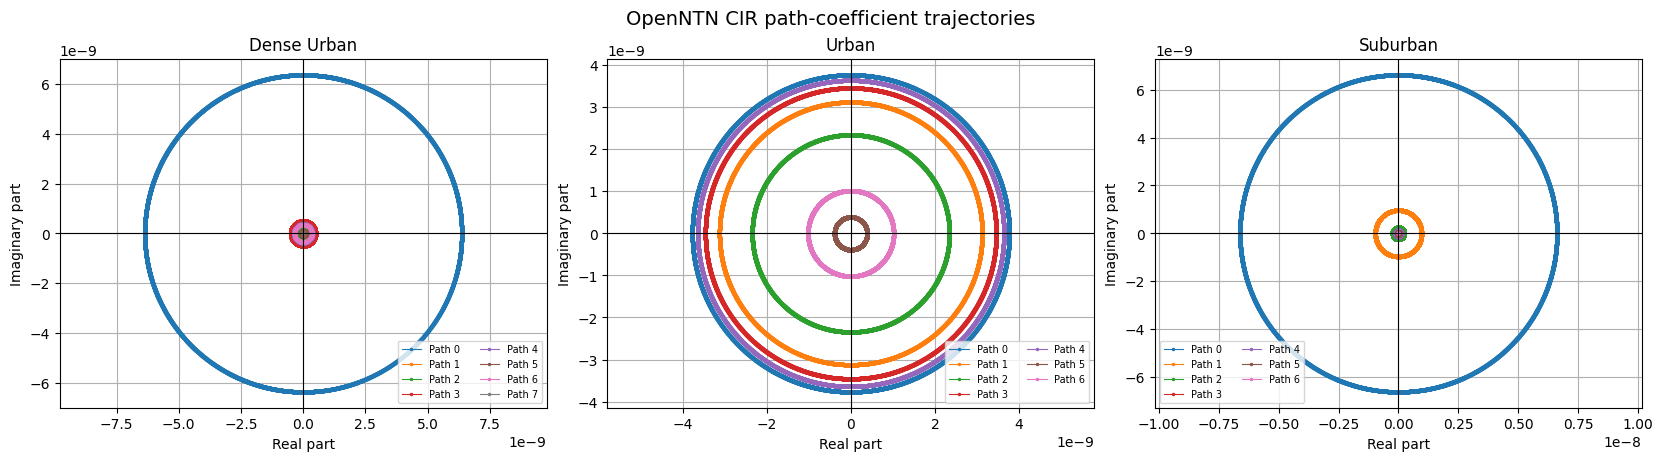

In [13]:

fig, axes = plt.subplots(1, len(ntn_data), figsize=(5.5 * len(ntn_data), 4.5), constrained_layout=True)

for ax, (name, data) in zip(axes, ntn_data.items()):
    a = data["a"].numpy()[0, 0, 0, 0, 0, :, :]
    num_paths = a.shape[0]

    for p in range(num_paths):
        ax.plot(
            np.real(a[p, :]),
            np.imag(a[p, :]),
            marker="o",
            markersize=1.5,
            linewidth=0.8,
            label=f"Path {p}" if p < 8 else None,
        )

    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(name)
    ax.set_xlabel("Real part")
    ax.set_ylabel("Imaginary part")
    ax.grid(True)
    ax.axis("equal")
    ax.legend(fontsize=7, ncol=2)

fig.suptitle("OpenNTN CIR path-coefficient trajectories", fontsize=14)
plt.show()


### 7.2 OpenNTN CIR: Path Amplitude over Time

Path amplitude evolution for the three NTN scenarios. The Dense Urban scenario shows the most amplitude variation across paths, consistent with its higher multipath richness. Urban and Suburban scenarios are dominated by a strong line-of-sight component with weaker delayed copies.

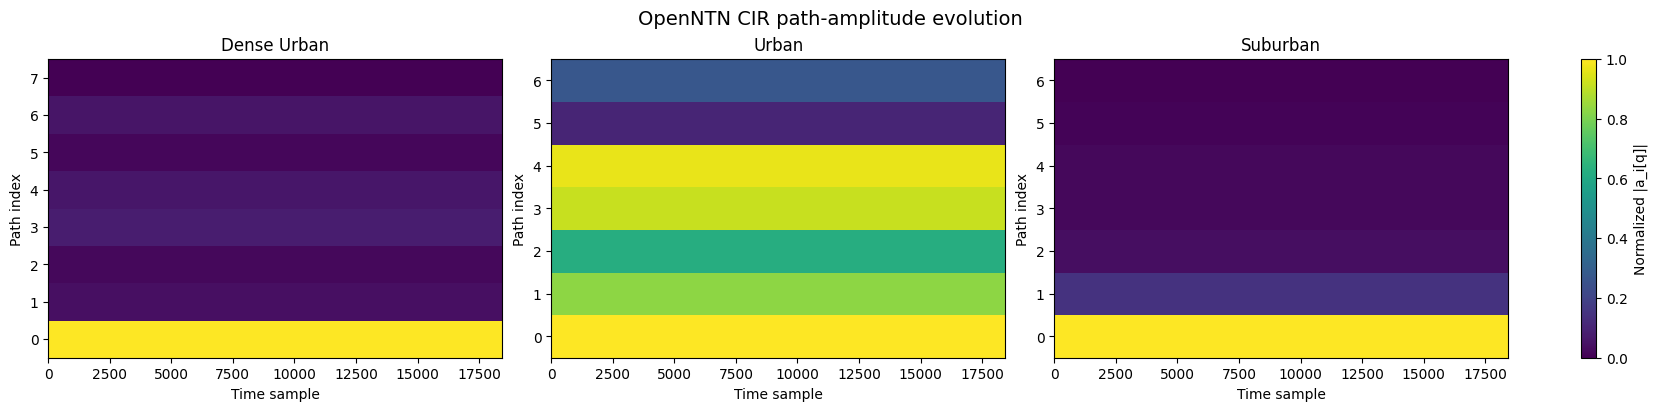

In [14]:

fig, axes = plt.subplots(1, len(ntn_data), figsize=(5.5 * len(ntn_data), 4), constrained_layout=True)

for ax, (name, data) in zip(axes, ntn_data.items()):
    a = data["a"].numpy()[0, 0, 0, 0, 0, :, :]
    amp = np.abs(a)
    amp = amp / (np.max(amp) + 1e-12)

    im = ax.imshow(
        amp,
        aspect="auto",
        origin="lower",
        cmap="viridis",
        vmin=0,
        vmax=1,
        interpolation="nearest",
    )
    ax.set_title(name)
    ax.set_xlabel("Time sample")
    ax.set_ylabel("Path index")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

fig.colorbar(im, ax=axes.ravel().tolist(), label="Normalized |a_i[q]|")
fig.suptitle("OpenNTN CIR path-amplitude evolution", fontsize=14)
plt.show()


### 7.3 OpenNTN CIR: Path Phase over Time

The phase evolution for all three NTN scenarios shows a rapid linear ramp across all paths -- the satellite Doppler shift. All paths share approximately the same Doppler value because the terminal-to-satellite geometry is common to all scatterers in the TR 38.811 model at this elevation angle.

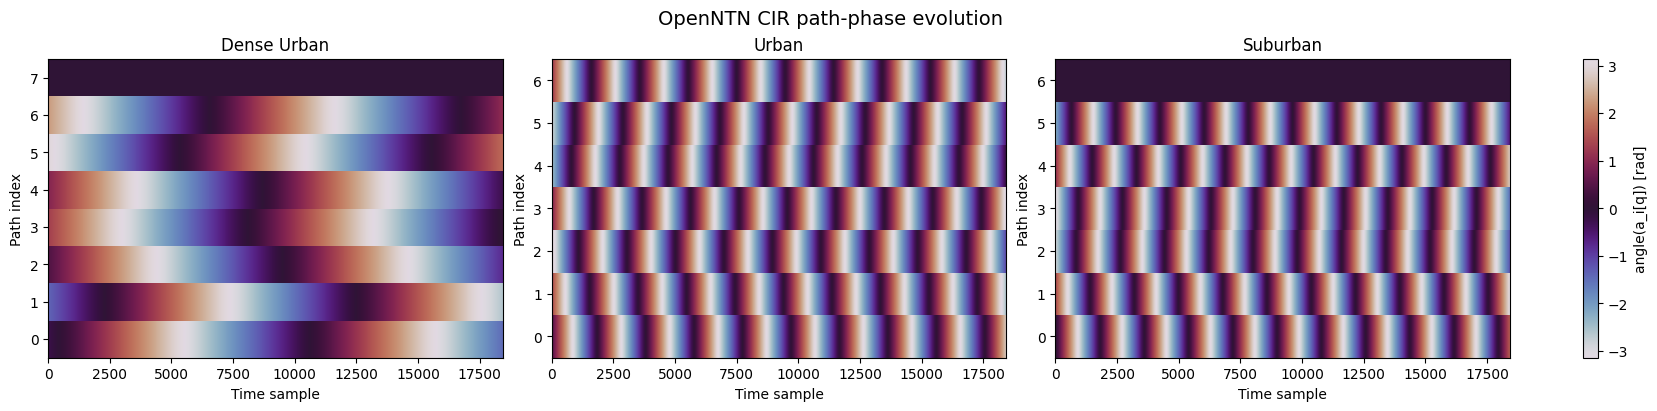

In [15]:

fig, axes = plt.subplots(1, len(ntn_data), figsize=(5.5 * len(ntn_data), 4), constrained_layout=True)

for ax, (name, data) in zip(axes, ntn_data.items()):
    a = data["a"].numpy()[0, 0, 0, 0, 0, :, :]
    phase = np.angle(a)

    im = ax.imshow(
        phase,
        aspect="auto",
        origin="lower",
        cmap="twilight",
        vmin=-np.pi,
        vmax=np.pi,
        interpolation="nearest",
    )
    ax.set_title(name)
    ax.set_xlabel("Time sample")
    ax.set_ylabel("Path index")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

fig.colorbar(im, ax=axes.ravel().tolist(), label="angle(a_i[q]) [rad]")
fig.suptitle("OpenNTN CIR path-phase evolution", fontsize=14)
plt.show()


### 7.4 OpenNTN `h_time`: Magnitude and Phase

The discrete time-varying channel `h_time` for the three NTN scenarios. The magnitude plot is cropped to the active delay region (taps above a small fraction of the peak). Dense Urban extends to more delay taps than Urban and Suburban, consistent with its wider delay spread.

The phase plot shows the common satellite Doppler ramp across all active taps in all three scenarios.

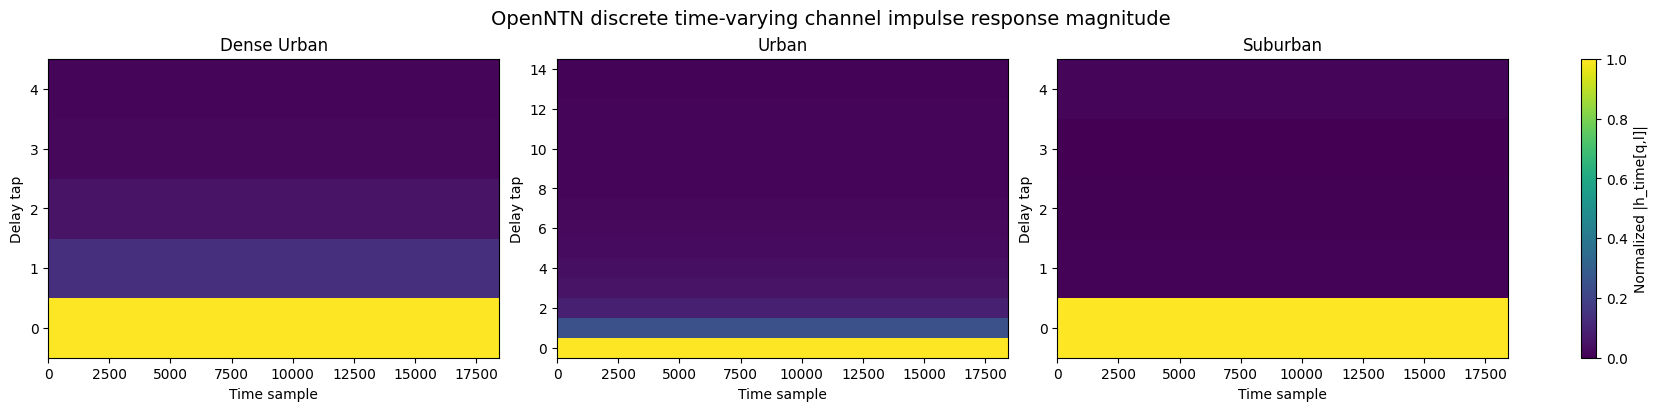

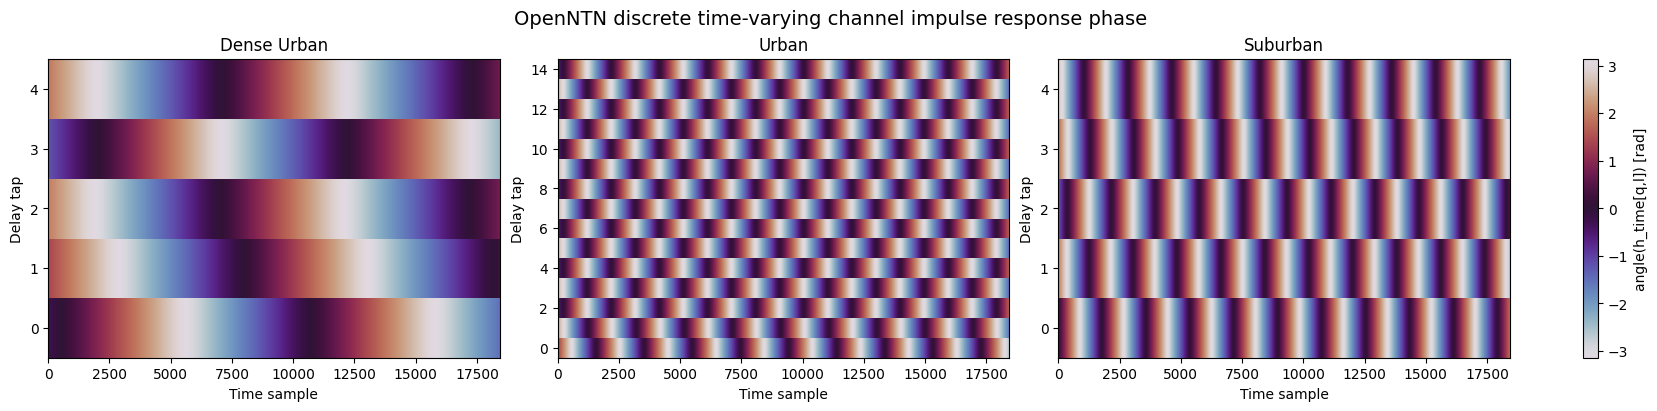

In [16]:

fig, axes = plt.subplots(1, len(ntn_data), figsize=(5.5 * len(ntn_data), 4), constrained_layout=True)

for ax, (name, data) in zip(axes, ntn_data.items()):
    h = data["h_time"].numpy()[0, 0, 0, 0, 0, :, :]
    h_abs = np.abs(h).T
    h_abs = h_abs / (np.max(h_abs) + 1e-12)
        
    delay_profile = np.max(np.abs(h), axis=0)
    threshold = 0.01 * np.max(delay_profile)
    active_delays = np.where(delay_profile > threshold)[0]
    # Zoom delay axis to the active delay support.
    if len(active_delays) > 0:
        max_delay = active_delays[-1]
    else:
        max_delay = h_abs.shape[1] - 1

    im = ax.imshow(
        h_abs,
        aspect="auto",
        origin="lower",
        cmap="viridis",
        vmin=0,
        vmax=1,
        interpolation="nearest",
    )
    ax.set_ylim(-0.5, max_delay + 0.5)
    ax.set_title(name)
    ax.set_xlabel("Time sample")
    ax.set_ylabel("Delay tap")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

fig.colorbar(im, ax=axes.ravel().tolist(), label="Normalized |h_time[q,l]|")
fig.suptitle("OpenNTN discrete time-varying channel impulse response magnitude", fontsize=14)
plt.show()

fig, axes = plt.subplots(1, len(ntn_data), figsize=(5.5 * len(ntn_data), 4), constrained_layout=True)

for ax, (name, data) in zip(axes, ntn_data.items()):
    h = data["h_time"].numpy()[0, 0, 0, 0, 0, :, :]
    phase = np.angle(h).T
    mask = np.abs(h).T < 1e-10
    phase = np.ma.array(phase, mask=mask)
    
    # Restrict the y-axis to delay taps with visible energy.
    delay_profile = np.max(np.abs(h), axis=0)
    threshold = 0.01 * np.max(delay_profile)
    active_delays = np.where(delay_profile > threshold)[0]
    if len(active_delays) > 0:
        max_delay = active_delays[-1]
    else:
        max_delay = h_abs.shape[1] - 1
    

    im = ax.imshow(
        phase,
        aspect="auto",
        origin="lower",
        cmap="twilight",
        vmin=-np.pi,
        vmax=np.pi,
        interpolation="nearest",
    )
    ax.set_ylim(-0.5, max_delay + 0.5)
    ax.set_title(name)
    ax.set_xlabel("Time sample")
    ax.set_ylabel("Delay tap")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

fig.colorbar(im, ax=axes.ravel().tolist(), label="angle(h_time[q,l]) [rad]")
fig.suptitle("OpenNTN discrete time-varying channel impulse response phase", fontsize=14)
plt.show()


### 7.5 OpenNTN Time-Frequency Representation

The time-frequency channel $H_\text{tf}[m, n]$ for the three NTN scenarios. The magnitude plot shows a relatively uniform gain across subcarriers (the delay spread is short relative to the OFDM bandwidth), with slow variation across OFDM symbols set by the channel coherence time.

The phase plot shows rapid diagonal variation induced by the satellite Doppler: each subcarrier accumulates a phase that is both frequency-dependent (from the delay spread) and time-dependent (from the Doppler shift), producing the characteristic diagonal banding.

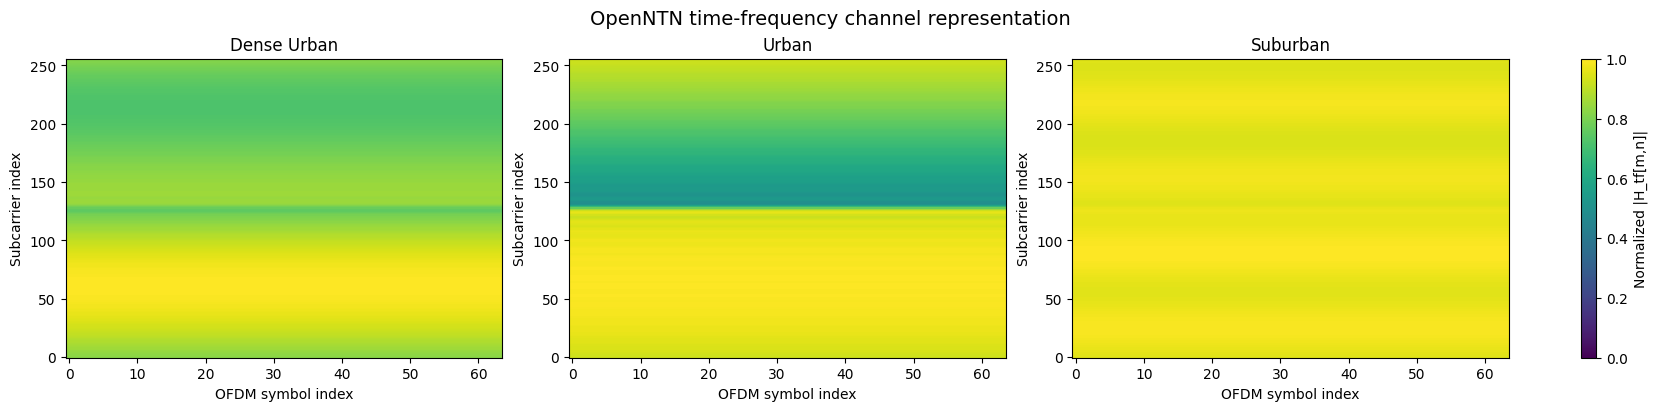

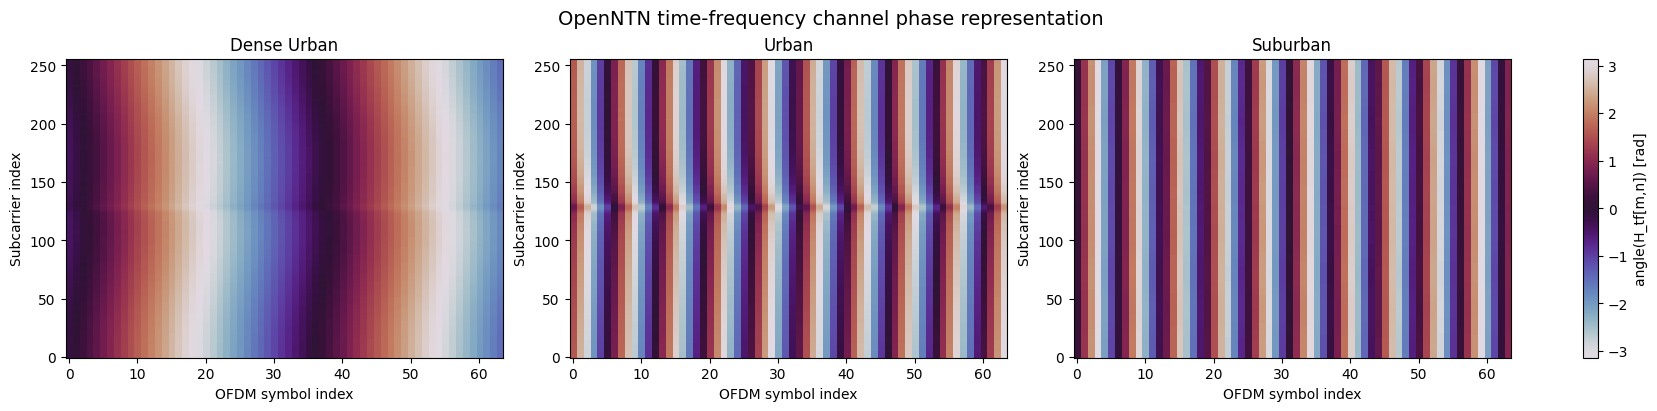

In [17]:
for name, data in ntn_data.items():
    h = data["h_time"].numpy()[0, 0, 0, 0, 0, :, :]
    num_delays = h.shape[1]

    H_tf = np.zeros(
        (NTN_NUM_OFDM_SYMBOLS, NTN_FFT_SIZE),
        dtype=np.complex128,
    )

    for n in range(NTN_NUM_OFDM_SYMBOLS):
        q = n * (NTN_FFT_SIZE + NTN_CP_LEN) + NTN_CP_LEN

        h_delay = np.zeros(NTN_FFT_SIZE, dtype=np.complex128)
        h_delay[:min(num_delays, NTN_FFT_SIZE)] = h[
            q,
            :min(num_delays, NTN_FFT_SIZE),
        ]

        H_tf[n, :] = np.fft.fft(h_delay, n=NTN_FFT_SIZE)

    ntn_data[name]["H_tf"] = H_tf


fig, axes = plt.subplots(
    1,
    len(ntn_data),
    figsize=(5.5 * len(ntn_data), 4),
    constrained_layout=True,
)

for ax, (name, data) in zip(axes, ntn_data.items()):
    H_abs = np.abs(data["H_tf"]).T
    H_abs = H_abs / (np.max(H_abs) + 1e-12)

    im = ax.imshow(
        H_abs,
        aspect="auto",
        origin="lower",
        cmap="viridis",
        vmin=0,
        vmax=1,
        interpolation="nearest",
    )
    ax.set_title(name)
    ax.set_xlabel("OFDM symbol index")
    ax.set_ylabel("Subcarrier index")

fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    label="Normalized |H_tf[m,n]|",
)
fig.suptitle("OpenNTN time-frequency channel representation", fontsize=14)
plt.show()


fig, axes = plt.subplots(
    1,
    len(ntn_data),
    figsize=(5.5 * len(ntn_data), 4),
    constrained_layout=True,
)

for ax, (name, data) in zip(axes, ntn_data.items()):
    H_phase = np.angle(data["H_tf"]).T

    im = ax.imshow(
        H_phase,
        aspect="auto",
        origin="lower",
        cmap="twilight",
        vmin=-np.pi,
        vmax=np.pi,
        interpolation="nearest",
    )
    ax.set_title(name)
    ax.set_xlabel("OFDM symbol index")
    ax.set_ylabel("Subcarrier index")

fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    label="angle(H_tf[m,n]) [rad]",
)
fig.suptitle("OpenNTN time-frequency channel phase representation", fontsize=14)
plt.show()


### 7.6 OpenNTN Approximate Delay-Doppler Representation

The OpenNTN channel is generated as a time-varying CIR. To visualize it in the delay-Doppler domain, approximate DD paths are extracted from the CIR using `approximate_dd_paths_from_cir`, and the delay-Doppler grid is reconstructed with both integer-bin placement and sinc-spread fractional Doppler kernels.

The printed path parameters confirm that all extracted paths cluster at nearly the same Doppler value for each scenario -- the dominant satellite velocity component. The delay axis shows the scenario-specific multipath structure, with Dense Urban having the widest spread and Suburban the most concentrated.

Two plots are shown:

- **Integer-bin approximation**: each path placed at its nearest integer Doppler bin. Shows the dominant delay-Doppler positions clearly.
- **Sinc-spread approximation**: fractional Doppler offsets produce leakage across adjacent Doppler bins, visible as horizontal smearing around the main lobe.

Dense Urban: extracted 8 approximate DD paths

Approximated DD paths
g_i = [ 6.15814377e-09-1.6303681e-09j  4.59373685e-11-2.6955760e-10j
  1.27401936e-10+5.8025140e-11j  1.36485032e-10+4.8064452e-10j
  2.25546345e-10+3.0253194e-10j -1.06518724e-10+1.6503188e-11j
 -2.23203248e-10+2.7200836e-10j  0.00000000e+00+0.0000000e+00j]
l_i = [       0        0        0        1        1        1        2 74615240]
k_i = [1.8095007 1.8095071 1.8095028 1.809505  1.8095012 1.8095044 1.8095056
 0.       ]
Urban: extracted 7 approximate DD paths

Approximated DD paths
g_i = [ 3.4018932e-09+1.6226459e-09j  5.0633564e-10+3.0817739e-09j
 -2.2492310e-09+6.6088374e-10j  2.1300752e-09+2.7237881e-09j
 -2.8818130e-09-2.2240199e-09j -3.7735420e-10-9.2869983e-11j
  3.6551959e-10+9.5089403e-10j]
l_i = [0 0 0 0 0 1 1]
k_i = [9.390505 9.390505 9.39052  9.390506 9.390501 9.390521 9.390503]
Suburban: extracted 7 approximate DD paths

Approximated DD paths
g_i = [ 6.5796635e-09-7.0363387e-10j  2.3368957e-10+9.387564

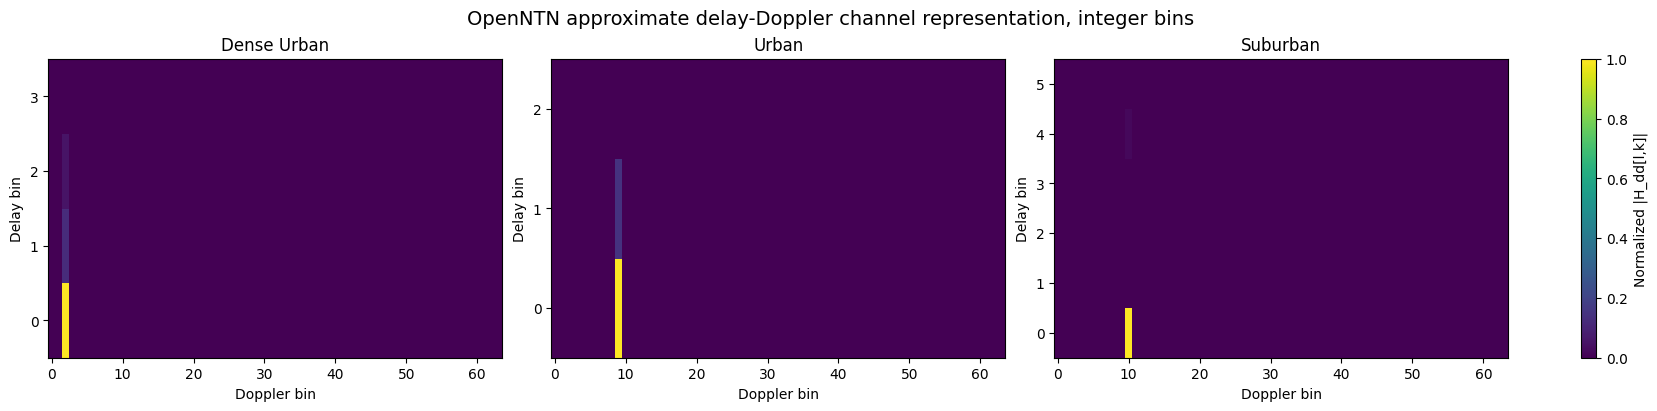

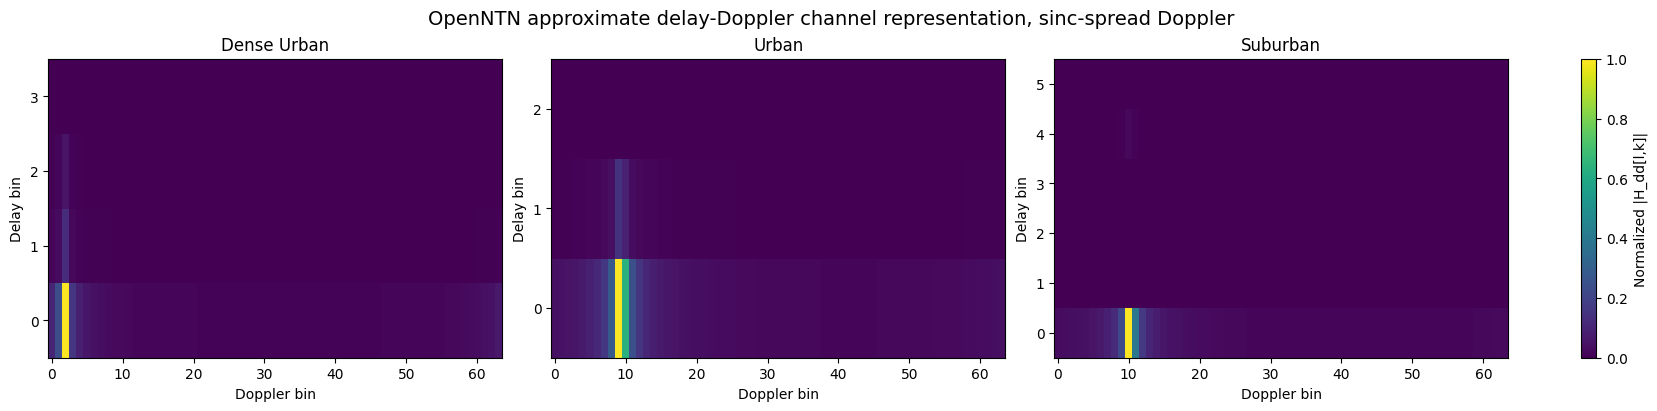

In [18]:

for name, data in ntn_data.items():
    # Extract approximate DD paths from the time-varying CIR for visualization only.
    g_i, l_i, k_i = approximate_dd_paths_from_cir(
        a=data["a"],
        tau=data["tau"],
        bandwidth=NTN_BANDWIDTH,
        frame_num_time_samples=NTN_NUM_TIME_SAMPLES_WITH_CP,
    )

    g_i = g_i.numpy()
    l_i = l_i.numpy()
    k_i = k_i.numpy()

    H_dd_integer = np.zeros(
        (NTN_FFT_SIZE, NTN_NUM_OFDM_SYMBOLS),
        dtype=np.complex128,
    )

    H_dd_sinc = np.zeros(
        (NTN_FFT_SIZE, NTN_NUM_OFDM_SYMBOLS),
        dtype=np.complex128,
    )

    for g, ell, k in zip(g_i, l_i, k_i):
        ell_int = int(np.round(ell))

        if not (0 <= ell_int < NTN_FFT_SIZE):
            continue

        # ----------------------------------------------------
        # 1) Integer-bin approximation
        # ----------------------------------------------------
        kk_int = int(np.round(k)) % NTN_NUM_OFDM_SYMBOLS
        H_dd_integer[ell_int, kk_int] += g

        # ----------------------------------------------------
        # 2) Fractional Doppler sinc-spread approximation
        # ----------------------------------------------------
        for kk in range(NTN_NUM_OFDM_SYMBOLS):
            d = kk - k

            # Periodic Doppler distance on an N-bin grid
            d = (
                (d + NTN_NUM_OFDM_SYMBOLS / 2)
                % NTN_NUM_OFDM_SYMBOLS
                - NTN_NUM_OFDM_SYMBOLS / 2
            )

            if np.abs(d) < 1e-12:
                sinc_kernel = 1.0
            else:
                sinc_kernel = (
                    np.sin(np.pi * d)
                    / (
                        NTN_NUM_OFDM_SYMBOLS
                        * np.sin(np.pi * d / NTN_NUM_OFDM_SYMBOLS)
                    )
                )

            H_dd_sinc[ell_int, kk] += g * sinc_kernel

    ntn_data[name]["H_dd_integer"] = H_dd_integer
    ntn_data[name]["H_dd_sinc"] = H_dd_sinc
    ntn_data[name]["g_i_approx"] = g_i
    ntn_data[name]["l_i_approx"] = l_i
    ntn_data[name]["k_i_approx"] = k_i

    print(f"{name}: extracted {len(g_i)} approximate DD paths")
    print("\nApproximated DD paths")
    print("g_i =", g_i)
    print("l_i =", l_i)
    print("k_i =", k_i)


# ============================================================
# Plot 1: integer-bin DD representation
# ============================================================

fig, axes = plt.subplots(
    1,
    len(ntn_data),
    figsize=(5.5 * len(ntn_data), 4),
    constrained_layout=True,
)

for ax, (name, data) in zip(axes, ntn_data.items()):
    H_abs = np.abs(data["H_dd_integer"])
    H_abs = H_abs / (np.max(H_abs) + 1e-12)

    im = ax.imshow(
        H_abs,
        aspect="auto",
        origin="lower",
        cmap="viridis",
        vmin=0,
        vmax=1,
    )

    ax.set_title(name)
    ax.set_xlabel("Doppler bin")
    ax.set_ylabel("Delay bin")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

    delay_profile = np.max(H_abs, axis=1)
    active_delays = np.where(delay_profile > 1e-3 * np.max(delay_profile))[0]

    if len(active_delays) > 0:
        ax.set_ylim(-0.5, active_delays[-1] + 1.5)

fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    label="Normalized |H_dd[l,k]|",
)

fig.suptitle(
    "OpenNTN approximate delay-Doppler channel representation, integer bins",
    fontsize=14,
)

plt.show()


# ============================================================
# Plot 2: fractional-Doppler sinc-spread DD representation
# ============================================================

fig, axes = plt.subplots(
    1,
    len(ntn_data),
    figsize=(5.5 * len(ntn_data), 4),
    constrained_layout=True,
)

for ax, (name, data) in zip(axes, ntn_data.items()):
    H_abs = np.abs(data["H_dd_sinc"])
    H_abs = H_abs / (np.max(H_abs) + 1e-12)

    im = ax.imshow(
        H_abs,
        aspect="auto",
        origin="lower",
        cmap="viridis",
        vmin=0,
        vmax=1,
    )

    ax.set_title(name)
    ax.set_xlabel("Doppler bin")
    ax.set_ylabel("Delay bin")
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

    delay_profile = np.max(H_abs, axis=1)
    active_delays = np.where(delay_profile > 1e-3 * np.max(delay_profile))[0]
    # Zoom delay axis to the active delay support.
    if len(active_delays) > 0:
        ax.set_ylim(-0.5, active_delays[-1] + 1.5)

fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    label="Normalized |H_dd[l,k]|",
)

fig.suptitle(
    "OpenNTN approximate delay-Doppler channel representation, sinc-spread Doppler",
    fontsize=14,
)

plt.show()

## 8. Summary

Working through all four representations for both synthetic and realistic channels establishes several concrete connections:

**CIR** is the ground truth -- everything else is a different basis for looking at the same underlying propagation. Static paths produce fixed points in the complex plane; Doppler-shifted paths rotate.

**`h_time`** is the computational workhorse. It is what the time-domain equalizer multiplies against, and it is the quantity reconstructed from pilot observations. Active delay taps appear at fixed positions; Doppler modulates their phase but not their magnitude.

**`H_tf`** is what OFDM naturally operates on. For static multipath it is time-invariant and the single-tap equalization assumption holds exactly. For doubly dispersive channels it changes with every OFDM symbol, becomes dense across the full $M \times N$ grid, and requires pilot overhead proportional to the frame size for direct estimation.

**`H_dd`** has at most $P$ non-zero entries for a $P$-path channel. OTFS exploits this sparsity both for modulation -- spreading information over the whole delay-Doppler grid so that all paths contribute to every received symbol -- and for estimation -- a single pilot illuminates all $P$ paths simultaneously.

The synthetic examples serve as controlled cases to build intuition; the NTN examples show that the same structure appears in TR 38.811-compliant realistic channels. Notebook 2 examines what these channels do to an OFDM frame specifically -- building the block channel matrices explicitly and quantifying the intercarrier interference that arises under Doppler.